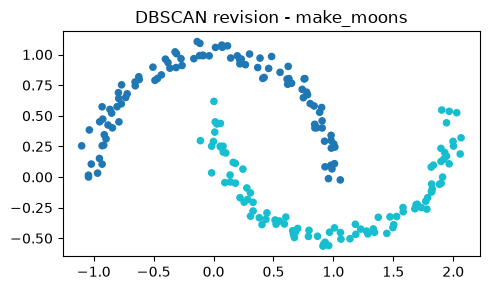

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
from sklearn.datasets import make_moons

# --- Quick revision snippet ---
X_rev, _ = make_moons(n_samples=200, noise=0.05, random_state=42)
db = DBSCAN(eps=0.2, min_samples=5)
labels_rev = db.fit_predict(X_rev)

plt.figure(figsize=(5, 3))
plt.scatter(X_rev[:, 0], X_rev[:, 1], c=labels_rev, cmap='tab10', s=20)
plt.title("DBSCAN revision - make_moons")
plt.tight_layout(); plt.show()

# Viva notes:
# - eps = neighborhood radius; points within eps of a core point are in same cluster
# - min_samples = minimum points in eps-neighborhood to be called a core point
# - label = -1 means noise (not part of any cluster)
# - DBSCAN does NOT need k pre-specified (unlike KMeans)
# - Handles arbitrary-shaped clusters and is robust to outliers


### Q15
Develop a Python program to implement DBSCAN using the sklearn library. Use a 2D dataset (ex. make_moons) for clustering.


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
from sklearn.datasets import make_moons


In [3]:
# Generate make_moons dataset
X, _ = make_moons(n_samples=300, noise=0.05, random_state=42)
print("Dataset shape:", X.shape)


Dataset shape: (300, 2)


In [4]:
# Apply DBSCAN
model = DBSCAN(eps=0.2, min_samples=5)
labels = model.fit_predict(X)

n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = list(labels).count(-1)
print(f"Number of clusters found: {n_clusters}")
print(f"Number of noise points  : {n_noise}")


Number of clusters found: 2
Number of noise points  : 0


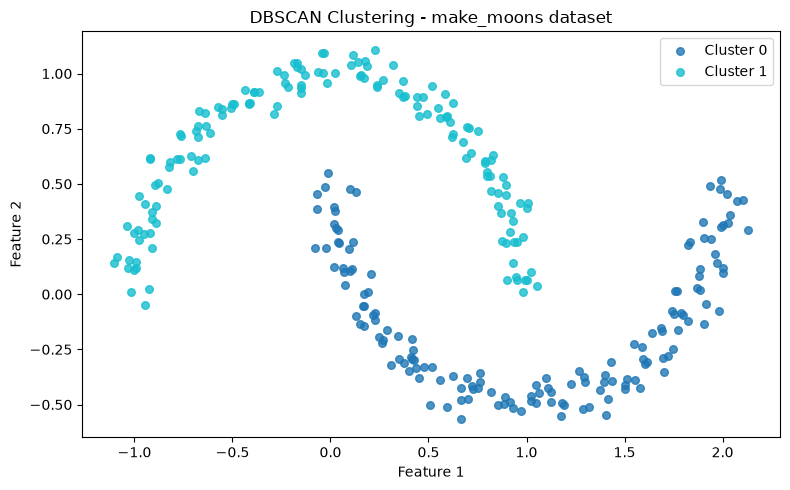

In [5]:
# Scatter plot - noise points in black, clusters in colors
plt.figure(figsize=(8, 5))
unique_labels = set(labels)
colors = plt.cm.tab10(np.linspace(0, 1, len(unique_labels)))

for lbl, col in zip(sorted(unique_labels), colors):
    mask = labels == lbl
    if lbl == -1:
        # Noise points
        plt.scatter(X[mask, 0], X[mask, 1], c='black', s=30,
                    marker='x', label='Noise', zorder=5)
    else:
        plt.scatter(X[mask, 0], X[mask, 1], color=col, s=30,
                    alpha=0.8, label=f"Cluster {lbl}")

plt.title("DBSCAN Clustering - make_moons dataset")
plt.xlabel("Feature 1"); plt.ylabel("Feature 2")
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()


### Q16
Generate a random dataset with 5 columns and use 3rd and 4th column as data to implement DBSCAN. Consider eps=5 and minPts=5.


In [6]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN


In [7]:
# Generate random dataset: 200 rows, 5 columns, scaled 0-100
np.random.seed(42)
data = np.random.rand(200, 5) * 100
print("Full dataset shape:", data.shape)

# Use 3rd and 4th columns (index 2 and 3)
X = data[:, 2:4]
print("Selected columns shape (3rd and 4th):", X.shape)
print("First 5 rows:\n", X[:5])


Full dataset shape: (200, 5)
Selected columns shape (3rd and 4th): (200, 2)
First 5 rows:
 [[73.19939418 59.86584842]
 [86.61761458 60.11150117]
 [83.24426408 21.23391107]
 [52.47564316 43.19450186]
 [29.21446485 36.63618433]]


In [8]:
# Apply DBSCAN with eps=5, min_samples=5 (minPts)
model = DBSCAN(eps=5, min_samples=5)
labels = model.fit_predict(X)

n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = list(labels).count(-1)
print(f"Number of clusters found: {n_clusters}")
print(f"Number of noise points  : {n_noise}")
print(f"Unique labels: {sorted(set(labels))}")


Number of clusters found: 5
Number of noise points  : 166
Unique labels: [np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]


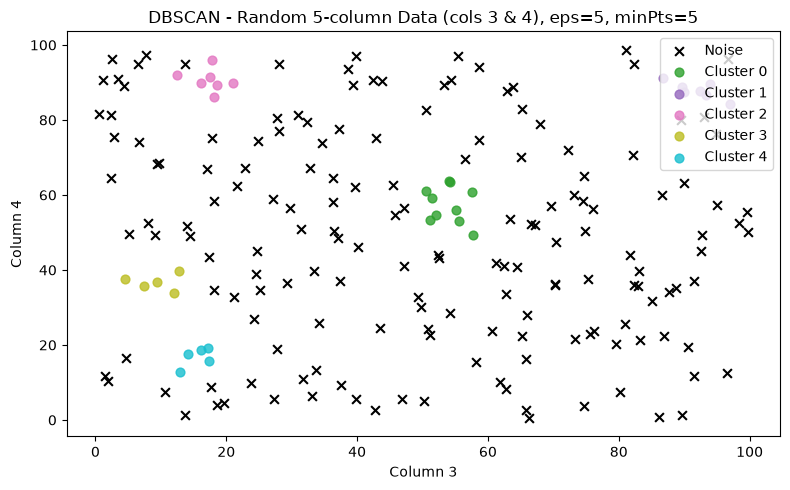

In [9]:
# Scatter plot colored by cluster label
plt.figure(figsize=(8, 5))
unique_labels = set(labels)
colors = plt.cm.tab10(np.linspace(0, 1, max(len(unique_labels), 1)))

for lbl, col in zip(sorted(unique_labels), colors):
    mask = labels == lbl
    if lbl == -1:
        plt.scatter(X[mask, 0], X[mask, 1], c='black', s=40,
                    marker='x', label='Noise', zorder=5)
    else:
        plt.scatter(X[mask, 0], X[mask, 1], color=col, s=40,
                    alpha=0.8, label=f"Cluster {lbl}")

plt.title("DBSCAN - Random 5-column Data (cols 3 & 4), eps=5, minPts=5")
plt.xlabel("Column 3"); plt.ylabel("Column 4")
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()
